# Detección temprana de daño en el puente Z24 con machine learning

Proyecto de machine learning sobre los datos del monitoreo continuo (EMS) del puente Z24. Se entrena un modelo que predice la frecuencia de cada modo a partir de la temperatura, solo con el puente sano, y se vigila la diferencia entre lo medido y lo predicho para detectar el daño lo antes posible.

Parte de los resultados de los notebooks de la carpeta superior: `results/ems_natural_frequencies.csv` (frecuencias de los modos 1, 2 y 3 en cada medición horaria, de `z24_natural_frequencies_ems.ipynb`) y `cache/ems_inventory.csv` (variables ambientales de cada medición, de `z24_data_structure.ipynb`).

**Índice**
1. [Definición del problema y alcance](#sec1)
2. [Selección y limpieza de datos](#sec2)

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

# Fixed seed, so that any random result is always the same
np.random.seed(42)

# Input files (they are in the parent folder, bridge-z24)
FREQUENCIES_FILE = "../results/ems_natural_frequencies.csv"
ENVIRONMENT_FILE = "../cache/ems_inventory.csv"

# Important dates
TEST_START = pd.Timestamp("1998-07-15")           # start of the healthy test block
PREP_START = pd.Timestamp("1998-08-05")           # start of the installation of the pier lowering system
DAMAGE_START = pd.Timestamp("1998-08-11 13:15")   # first pier lowering, -20 mm (Table 8, Appendix F of C11)


# Shows a table with its caption above it (decimal numbers are shown with the given number of decimals)
def show_table(table, number, caption, decimals=2):
    display(Markdown(f"**Tabla {number}.** {caption}"))
    display(table.style.hide(axis="index").format(precision=decimals))


# Shows a figure with its caption below it
def show_figure(fig, number, caption):
    display(fig)
    plt.close(fig)
    display(Markdown(f"**Figura {number}.** {caption}"))

---
<a id="sec1"></a>
## 1. Definición del problema y alcance

### 1.1 Problema

- El daño reduce la rigidez del puente y, por lo tanto, sus frecuencias naturales. Vigilar las frecuencias es una forma barata de detectar daño.
- Pero la temperatura también cambia las frecuencias, y en Z24 lo hace en un orden parecido al del daño. Bajo 0 °C el cambio es mayor y no lineal, porque el asfalto y el suelo se congelan y rigidizan el puente.
- Si se compara la frecuencia medida con la de todo el año, el daño queda escondido dentro de la variación por temperatura (Figura 1).

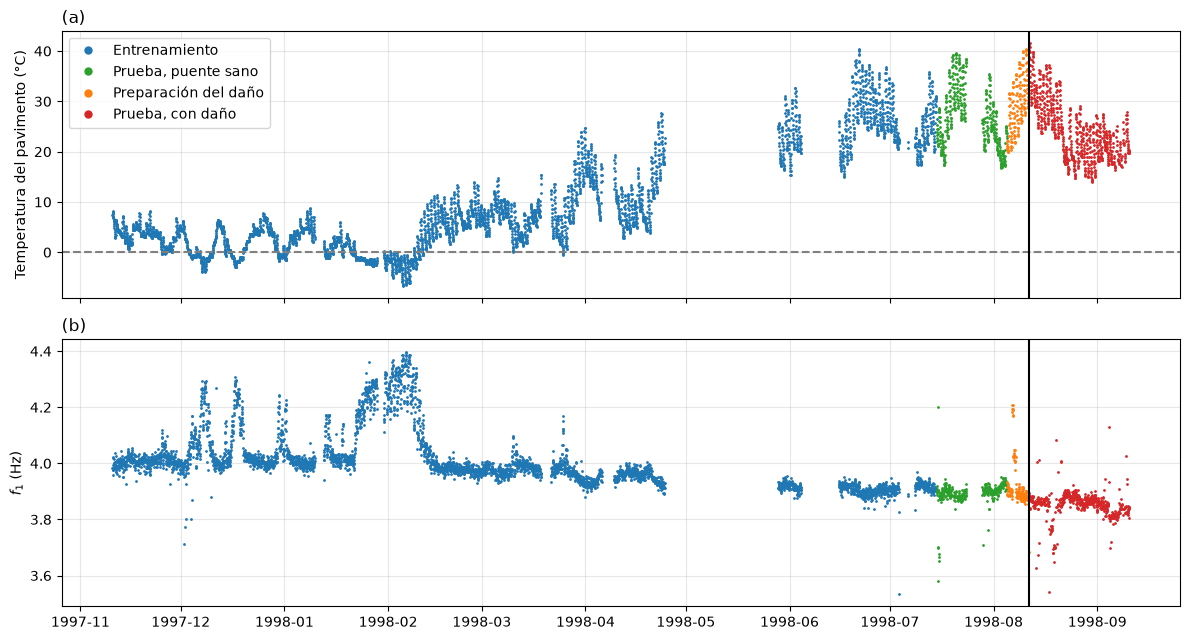

**Figura 1.** Monitoreo del Z24, del 10.11.1997 al 10.09.1998: (a) temperatura del pavimento y (b) frecuencia del modo 1. Los colores son los bloques de tiempo del proyecto (sección 1.5). La línea vertical marca el primer daño (descenso de la pila, 11.08.1998, 13:15) y la discontinua de (a), 0 °C.

In [2]:
# 1. Read the natural frequencies (f1, f2, f3) of each hourly measurement
frequencies = pd.read_csv(FREQUENCIES_FILE, parse_dates=["start"])

# 2. Read the two pavement temperature sensors (TP1 and TP2) of each measurement
temperatures = pd.read_csv(ENVIRONMENT_FILE, usecols=["code", "TP1", "TP2"])

# 3. Some readings are error codes of the data logger (for example 3276.7).
#    A real temperature is never above 100 °C, so those values are replaced by NaN (empty)
temperatures.loc[temperatures["TP1"].abs() >= 100, "TP1"] = np.nan
temperatures.loc[temperatures["TP2"].abs() >= 100, "TP2"] = np.nan

# 4. Pavement temperature T = average of the two sensors (if one is empty, the other one is used)
temperatures["T"] = temperatures[["TP1", "TP2"]].mean(axis=1)

# 5. Join both tables using the code of the measurement
data = pd.merge(frequencies, temperatures[["code", "T"]], on="code", how="left")


# 6. Assign each measurement to a time block (Section 1.5)
def get_block(date):
    if date < TEST_START:
        return "Entrenamiento"
    elif date < PREP_START:
        return "Prueba, puente sano"
    elif date < DAMAGE_START:
        return "Preparación del daño"
    else:
        return "Prueba, con daño"


data["block"] = data["start"].apply(get_block)

# 7. Plot the temperature and f1 over time, with one color per block
BLOCK_COLORS = {
    "Entrenamiento": "tab:blue",
    "Prueba, puente sano": "tab:green",
    "Preparación del daño": "tab:orange",
    "Prueba, con daño": "tab:red",
}

fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)

for block, color in BLOCK_COLORS.items():
    block_data = data[data["block"] == block]
    axes[0].plot(block_data["start"], block_data["T"], ".", markersize=2, color=color, label=block)
    axes[1].plot(block_data["start"], block_data["f1"], ".", markersize=2, color=color)

# (a) Temperature
axes[0].axhline(0, color="gray", linestyle="--")        # 0 °C
axes[0].axvline(DAMAGE_START, color="black")            # first damage
axes[0].set_ylabel("Temperatura del pavimento (°C)")
axes[0].set_title("(a)", loc="left")
axes[0].legend(markerscale=5, loc="upper left")
axes[0].grid(alpha=0.3)

# (b) Natural frequency of mode 1
axes[1].axvline(DAMAGE_START, color="black")            # first damage
axes[1].set_ylabel("$f_1$ (Hz)")
axes[1].set_title("(b)", loc="left")
axes[1].grid(alpha=0.3)

fig.tight_layout()
show_figure(fig, 1, "Monitoreo del Z24, del 10.11.1997 al 10.09.1998: (a) temperatura del pavimento y (b) "
            "frecuencia del modo 1. Los colores son los bloques de tiempo del proyecto (sección 1.5). La línea "
            "vertical marca el primer daño (descenso de la pila, 11.08.1998, 13:15) y la discontinua de (a), 0 °C.")

- La frecuencia del modo 1 sube en invierno y baja en verano, siguiendo a la temperatura. Los picos más altos coinciden con las heladas.
- Con daño (rojo), $f_1$ baja unos 0.05 Hz respecto al verano sano, mientras que entre invierno y verano la temperatura la mueve más de 0.4 Hz.
- Además, el daño ocurre en la época más caliente, cuando $f_1$ ya es la más baja del año. Sin corregir por temperatura, cuesta separar el efecto del daño del efecto del calor.
- Hay mediciones sueltas muy alejadas de la nube (por ejemplo, bajo 3.7 Hz). Se tratan en la sección 2.4.

### 1.2 Objetivo

Detectar el daño del Z24 lo antes posible y con pocas falsas alarmas, quitando primero el efecto de la temperatura con un modelo de machine learning.

**Pregunta del proyecto:** con una tasa de falsas alarmas fijada en el puente sano, ¿cuántas horas después del primer daño se detecta?

### 1.3 Enfoque

Es un problema de **detección de novedades** (*novelty detection*): el modelo se entrena solo con el puente sano y aprende lo que es "normal". Las etiquetas de sano y dañado no se usan para entrenar, solo para evaluar.

1. **Modelo de regresión:** predice la frecuencia de cada modo, $\hat{f}_m$, a partir de la temperatura y de las variables que se derivan de ella (sección 1.4).
2. **Residuo:** diferencia entre lo medido y lo predicho,

$$
r_{m,i} = f_{m,i} - \hat{f}_m(\mathbf{x}_i)
\tag{1}
$$

donde $f_{m,i}$ es la frecuencia medida del modo $m$ en la medición $i$, $\mathbf{x}_i$ el vector de variables de entrada de esa medición y $\hat{f}_m(\mathbf{x}_i)$ la frecuencia que predice el modelo. Si el modelo es bueno, en el puente sano el residuo es pequeño y no depende de la temperatura.

3. **Índice de daño:** los residuos de los tres modos se combinan en uno solo con la distancia de Mahalanobis, que tiene en cuenta que los residuos de los modos están correlacionados.
4. **Carta de control:** el índice se suaviza con una media móvil exponencial (EWMA, *Exponentially Weighted Moving Average*), que da más peso a las mediciones recientes:

$$
z_i = \lambda\, d_i + (1 - \lambda)\, z_{i-1}
\tag{2}
$$

donde $d_i$ es el índice de daño de la medición $i$, $z_i$ el valor suavizado y $\lambda \in (0, 1]$ el peso de la medición nueva. Con $\lambda$ pequeño, el ruido de una hora no dispara la alarma, pero un cambio que se mantiene sí. Se comparará también con CUSUM (suma acumulada).

5. **Alarma:** cuando $z_i$ pasa un límite calibrado con los residuos del puente sano que el modelo no vio.

### 1.4 Variables

**Tabla 1.** Variables del modelo.

| Tipo | Variable | Por qué |
|---|---|---|
| Salida | $f_1$, $f_2$, $f_3$ (Hz) | Frecuencias de los tres modos identificados en el EMS |
| Entrada | Temperatura del pavimento, $T$ (°C), promedio de `TP1` y `TP2` | Es la que más se correlaciona con las frecuencias; bajo 0 °C la rigidización viene del asfalto |
| Entrada | Medias móviles de $T$ (6, 12 y 24 h) | El puente tarda en calentarse y enfriarse (inercia térmica) |
| Entrada, variante A | Horas seguidas con $T < 0$ °C | La rigidización depende de cuánto tiempo lleva congelado el puente |
| Entrada, variante B | Grados-hora de helada: suma $-T$ en cada hora bajo 0 °C y resta $T$ en cada hora sobre 0 °C, sin bajar de 0 | Mide también la intensidad de la helada y hace gradual el deshielo |

- Se prueba primero la variante A, después la B y después las dos juntas, y se queda la que dé mejores resultados.
- La humedad, el viento y las otras temperaturas (aire, suelo, cajón) no se usan. La sección 2 muestra con las gráficas de frecuencia frente a temperatura por qué basta con la del pavimento y su historia.

### 1.5 División temporal de los datos

**Por qué no al azar.** Las mediciones horarias seguidas son casi iguales: la temperatura y la frecuencia cambian poco de una hora a la siguiente. Con una división aleatoria, cada hora de prueba tendría a sus vecinas en el entrenamiento, y el modelo acertaría por haber visto casi el mismo dato (fuga de datos, *data leakage*). El error saldría demasiado optimista. En el monitoreo real el modelo siempre predice semanas que no vio, y la división tiene que imitar eso.

**División.** Los datos se separan en bloques de tiempo (Tabla 2 y colores de la Figura 1):

- **Entrenamiento**, con validación cruzada por semanas: el bloque se divide en $k$ folds formados por semanas completas. Cada fold se predice con un modelo entrenado con los demás. Así:
  - se eligen el modelo, la variante de helada y los hiperparámetros;
  - cada hora del entrenamiento, también las de helada, recibe una predicción de un modelo que no vio su semana. Con esos residuos se calibra el límite de alarma y se miden las falsas alarmas bajo y sobre 0 °C.
- **Prueba, puente sano:** las 3 semanas antes de la preparación del daño. No se usa para ajustar nada. Comprueba las falsas alarmas en las mismas condiciones (verano) que el periodo con daño.
- **Prueba, con daño:** mide el retraso de detección.

Una semana es más larga que la inercia térmica del puente (horas a pocos días), así que las semanas de distintos folds no se parecen hora a hora. En la sección de entrenamiento se comprueba con la autocorrelación de los residuos.

In [3]:
# What each block is used for
BLOCK_USE = {
    "Entrenamiento": "Validación cruzada por semanas: elegir el modelo y calibrar el límite de alarma con todas las temperaturas",
    "Prueba, puente sano": "Comprobar las falsas alarmas en las condiciones del periodo con daño (verano)",
    "Preparación del daño": "Se excluye de todo el proyecto: la instalación del sistema para bajar la pila cambió las frecuencias",
    "Prueba, con daño": "Medir el retraso de detección y el porcentaje de horas detectadas",
}

# One row per block: first date, last date and number of measurements
rows = []
for block in BLOCK_COLORS:
    block_data = data[data["block"] == block]
    rows.append({
        "Bloque": block,
        "Desde": block_data["start"].min().strftime("%d.%m.%Y %H:%M"),
        "Hasta": block_data["start"].max().strftime("%d.%m.%Y %H:%M"),
        "Mediciones": len(block_data),
        "Uso": BLOCK_USE[block],
    })
blocks_table = pd.DataFrame(rows)

show_table(blocks_table, 2, "Bloques de tiempo del proyecto.")

**Tabla 2.** Bloques de tiempo del proyecto.

Bloque,Desde,Hasta,Mediciones,Uso
Entrenamiento,10.11.1997 14:00,14.07.1998 23:00,4431,Validación cruzada por semanas: elegir el modelo y calibrar el límite de alarma con todas las temperaturas
"Prueba, puente sano",15.07.1998 00:00,04.08.1998 23:00,390,Comprobar las falsas alarmas en las condiciones del periodo con daño (verano)
Preparación del daño,05.08.1998 00:00,11.08.1998 13:00,158,Se excluye de todo el proyecto: la instalación del sistema para bajar la pila cambió las frecuencias
"Prueba, con daño",11.08.1998 14:00,10.09.1998 13:00,674,Medir el retraso de detección y el porcentaje de horas detectadas


**Folds de la validación cruzada.** En la Figura 1 el azul es todo el entrenamiento y el verde la prueba sana. Dentro del entrenamiento, la validación cruzada separa además semanas de validación, que cambian en cada fold:

- Cada medición recibe un número de semana, contado desde la primera medición (semana 0, 1, 2, ...).
- Las semanas se reparten por turnos en $k = 5$ folds: la semana 0 va al fold 1, la 1 al fold 2, ..., la 4 al fold 5, la 5 de nuevo al fold 1, y así sucesivamente.
- En cada vuelta de la validación, un fold es la validación y los otros cuatro el entrenamiento.

Al repartir por turnos, cada fold tiene semanas de todo el año, de invierno a verano (Figura 2 y Tabla 3).

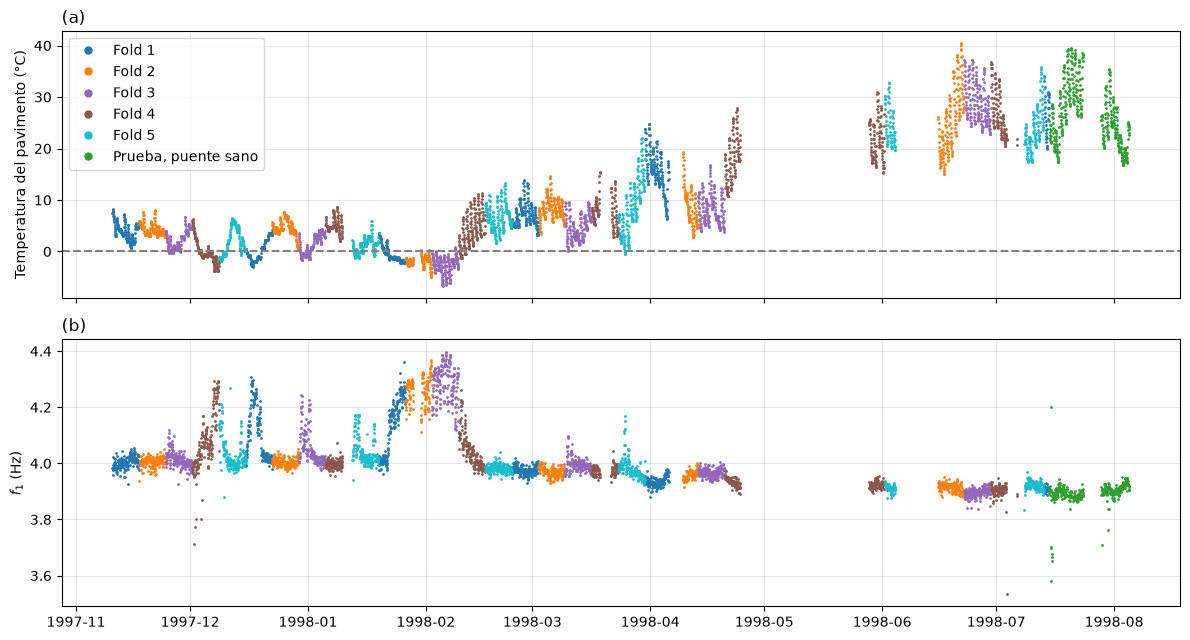

**Figura 2.** Folds de la validación cruzada en el bloque de entrenamiento (10.11.1997 al 14.07.1998) y prueba sana (15.07.1998 al 04.08.1998): (a) temperatura del pavimento y (b) frecuencia del modo 1. Cada color es un fold; cada tramo de un color es una semana completa. La línea discontinua de (a) marca 0 °C.

**Tabla 3.** Semanas, mediciones y rango de temperatura del pavimento de cada fold.

Fold,Semanas,Mediciones,T mínima (°C),T máxima (°C),Mediciones bajo 0 °C
1,6,855,-3.0,34.1,214
2,6,874,-5.0,40.4,119
3,6,1008,-6.7,37.3,237
4,7,831,-3.9,36.7,128
5,6,863,-1.8,35.7,101


In [4]:
# 1. Keep only the training block
training = data[data["block"] == "Entrenamiento"].copy()

# 2. Week number of each measurement, counted from the first measurement (week 0, 1, 2, ...)
first_date = training["start"].min()
training["week"] = (training["start"] - first_date).dt.days // 7

# 3. Assign the weeks to the folds in turn: week 0 -> fold 1, week 1 -> fold 2, ..., week 5 -> fold 1 again
N_FOLDS = 5
training["fold"] = training["week"] % N_FOLDS + 1

# 4. Plot the temperature and f1 over time, with one color per fold
FOLD_COLORS = {1: "tab:blue", 2: "tab:orange", 3: "tab:purple", 4: "tab:brown", 5: "tab:cyan"}
healthy_test = data[data["block"] == "Prueba, puente sano"]

fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)

for fold, color in FOLD_COLORS.items():
    fold_data = training[training["fold"] == fold]
    axes[0].plot(fold_data["start"], fold_data["T"], ".", markersize=2, color=color, label=f"Fold {fold}")
    axes[1].plot(fold_data["start"], fold_data["f1"], ".", markersize=2, color=color)

axes[0].plot(healthy_test["start"], healthy_test["T"], ".", markersize=2, color="tab:green", label="Prueba, puente sano")
axes[1].plot(healthy_test["start"], healthy_test["f1"], ".", markersize=2, color="tab:green")

# (a) Temperature
axes[0].axhline(0, color="gray", linestyle="--")        # 0 °C
axes[0].set_ylabel("Temperatura del pavimento (°C)")
axes[0].set_title("(a)", loc="left")
axes[0].legend(markerscale=5, loc="upper left")
axes[0].grid(alpha=0.3)

# (b) Natural frequency of mode 1
axes[1].set_ylabel("$f_1$ (Hz)")
axes[1].set_title("(b)", loc="left")
axes[1].grid(alpha=0.3)

fig.tight_layout()
show_figure(fig, 2, "Folds de la validación cruzada en el bloque de entrenamiento (10.11.1997 al 14.07.1998) y "
            "prueba sana (15.07.1998 al 04.08.1998): (a) temperatura del pavimento y (b) frecuencia del modo 1. Cada "
            "color es un fold; cada tramo de un color es una semana completa. La línea discontinua de (a) marca 0 °C.")

# 5. Table: weeks, measurements and temperature range of each fold
rows = []
for fold in FOLD_COLORS:
    fold_data = training[training["fold"] == fold]
    rows.append({
        "Fold": fold,
        "Semanas": fold_data["week"].nunique(),
        "Mediciones": len(fold_data),
        "T mínima (°C)": fold_data["T"].min(),
        "T máxima (°C)": fold_data["T"].max(),
        "Mediciones bajo 0 °C": (fold_data["T"] < 0).sum(),
    })
folds_table = pd.DataFrame(rows)

show_table(folds_table, 3, "Semanas, mediciones y rango de temperatura del pavimento de cada fold.", decimals=1)

- Los cinco folds tienen entre 6 y 7 semanas y entre 831 y 1008 mediciones.
- Todos cubren casi todo el rango de temperatura, de bajo 0 °C a más de 34 °C, y todos tienen entre 101 y 237 mediciones con helada. Así, cada fold de validación pone a prueba al modelo en invierno y en verano.
- La semana más fría (hasta −6.7 °C) queda en el fold 3. Cuando ese fold es la validación, el modelo no vio temperaturas tan bajas y tiene que extrapolar.

- **Preparación del daño.** Del 05.08.1998 al primer descenso de la pila se instaló el sistema para bajarla: se cortaron tres tramos de la pila Koppigen y se reemplazaron por piezas de acero con gatos hidráulicos (Tabla 2 de `z24_modal_distributions.ipynb`). Eso cambió el puente sano, por ejemplo $f_2$ quedó debajo de la nube del resto del periodo sano. Por eso estas mediciones se excluyen del entrenamiento, de la prueba y de las métricas, como en ese notebook, donde el puente sano es solo lo anterior al 05.08.1998.
- La prueba sana termina el 04.08.1998 y la prueba con daño empieza el 11.08.1998. La carta de control pasa del último dato sano al primero con daño, saltándose la preparación.
- **Limitación.** La semana más fría (2 al 8 de febrero de 1998, hasta −6.7 °C) no tiene otra parecida. En el fold en que queda fuera del entrenamiento, el modelo tiene que extrapolar, y su error será mayor. Es lo que pasaría con un invierno más frío que el de los datos.

### 1.6 Métricas

- **Del modelo:** RMSE (*root mean square error*, raíz del error cuadrático medio) de los residuos en la validación cruzada (por separado bajo y sobre 0 °C) y en la prueba sana.
- **De la detección:**
  - Tasa de falsas alarmas: porcentaje de horas en alarma en la validación cruzada (bajo y sobre 0 °C) y en la prueba sana.
  - Retraso de detección: horas desde el primer daño (11.08.1998, 13:15) hasta la primera alarma.
  - Porcentaje de horas en alarma en la prueba con daño.
  - Curva ROC (*Receiver Operating Characteristic*): detecciones frente a falsas alarmas para todos los límites posibles.
- **Comparación:** sin corrección por temperatura, con el modelo bilineal (`z24_modal_distributions.ipynb`) y con los modelos de machine learning, de menos a más complejo (regresión lineal, proceso gaussiano o gradient boosting, red neuronal pequeña).

### 1.7 Fuera del alcance

- La identificación modal desde las aceleraciones: se parte de las frecuencias ya identificadas.
- Localizar o cuantificar el daño: solo se detecta.
- Las formas modales.
- Otros puentes.

---
<a id="sec2"></a>
## 2. Selección y limpieza de datos

### 2.1 Selección de las variables

La Figura 3 muestra la frecuencia de cada modo frente a la temperatura del pavimento en el bloque de entrenamiento.

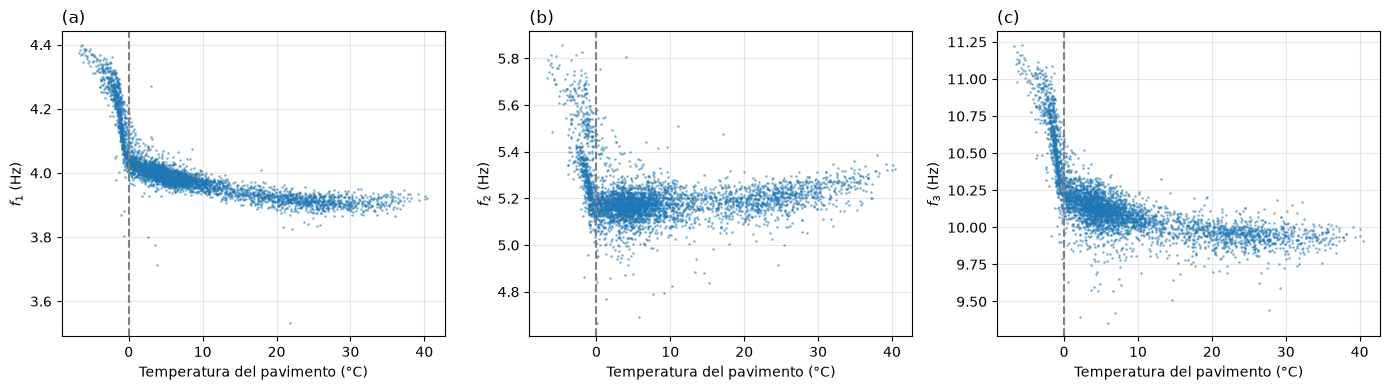

**Figura 3.** Frecuencia natural frente a la temperatura del pavimento en el bloque de entrenamiento (10.11.1997 al 14.07.1998): (a) modo 1, (b) modo 2 y (c) modo 3. La línea discontinua marca 0 °C.

In [5]:
PANEL_LABELS = ["(a)", "(b)", "(c)"]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for i, mode in enumerate([1, 2, 3]):
    axes[i].plot(training["T"], training[f"f{mode}"], ".", markersize=2, alpha=0.4)
    axes[i].axvline(0, color="gray", linestyle="--")     # 0 °C
    axes[i].set_xlabel("Temperatura del pavimento (°C)")
    axes[i].set_ylabel(f"$f_{mode}$ (Hz)")
    axes[i].set_title(PANEL_LABELS[i], loc="left")
    axes[i].grid(alpha=0.3)

fig.tight_layout()
show_figure(fig, 3, "Frecuencia natural frente a la temperatura del pavimento en el bloque de entrenamiento "
            "(10.11.1997 al 14.07.1998): (a) modo 1, (b) modo 2 y (c) modo 3. La línea discontinua marca 0 °C.")

- **La relación no es lineal.** Sobre 0 °C, $f_1$ y $f_3$ bajan poco a poco al subir la temperatura, y $f_2$ casi no cambia (hasta sube un poco con el calor). Bajo 0 °C las tres suben con fuerza: el asfalto se congela y rigidiza el puente. Una recta no puede representar los dos tramos, y por eso se prueban modelos no lineales.
- **La temperatura sola no basta.** Entre −1 y 0 °C, con casi la misma temperatura, $f_1$ va de unos 4.05 a 4.3 Hz. La diferencia depende de cuánto tiempo lleva helando: el asfalto tarda en congelarse y en descongelarse. Por eso se agregan las medias móviles de la temperatura y el tiempo bajo cero (Tabla 1). Se calculan en la sección 3.
- Las otras variables ambientales (humedad, viento, temperaturas del aire y del suelo) no se usan (sección 1.4).

### 2.2 Valores faltantes

Una medición puede no tener la frecuencia de un modo porque en `z24_natural_frequencies_ems.ipynb` no se identificó ese modo (MAC menor que 0.7 con la forma de referencia). La temperatura puede faltar si los dos sensores del pavimento dieron un código de error.

In [6]:
# Number of empty values (NaN) of each variable in each block
rows = []
for block in BLOCK_COLORS:
    block_data = data[data["block"] == block]
    rows.append({
        "Bloque": block,
        "Mediciones": len(block_data),
        "f1 vacía": block_data["f1"].isna().sum(),
        "f2 vacía": block_data["f2"].isna().sum(),
        "f3 vacía": block_data["f3"].isna().sum(),
        "T vacía": block_data["T"].isna().sum(),
    })
missing_table = pd.DataFrame(rows)

show_table(missing_table, 4, "Mediciones sin frecuencia o sin temperatura en cada bloque.")

**Tabla 4.** Mediciones sin frecuencia o sin temperatura en cada bloque.

Bloque,Mediciones,f1 vacía,f2 vacía,f3 vacía,T vacía
Entrenamiento,4431,6,88,90,0
"Prueba, puente sano",390,47,2,43,0
Preparación del daño,158,4,0,47,0
"Prueba, con daño",674,103,12,135,1


- En el entrenamiento faltan sobre todo $f_2$ y $f_3$ (unas 90 mediciones cada una, el 2 %). La temperatura falta en una sola medición, del periodo con daño.
- En el periodo con daño falta mucho más: 180 de 674 mediciones (27 %) no tienen alguna frecuencia (Tabla 6). Posiblemente el daño cambia las formas modales y el MAC con la forma de referencia del puente sano baja de 0.7. Eso también es una señal de daño, pero este proyecto solo usa las frecuencias identificadas (limitación).
- **Decisión:** se eliminan las mediciones a las que les falta alguna frecuencia o la temperatura. No se rellenan (imputan): una frecuencia inventada no aporta información del puente, y el índice de daño (sección 1.3) necesita los tres modos a la vez.
- La temperatura de esas mediciones sí se usa para calcular la historia de la temperatura (sección 3), porque la temperatura existe aunque falte la frecuencia.

### 2.3 Huecos en el tiempo

El EMS mide cada hora, pero hay horas sin medición. Los huecos importan para las variables de la sección 3: una media móvil de 24 h o las horas seguidas bajo cero no se pueden calcular bien si faltan días.

In [7]:
# 1. Sort all the measurements by date
all_measurements = data.sort_values("start").copy()

# 2. Hours between each measurement and the previous one
all_measurements["previous_start"] = all_measurements["start"].shift(1)
all_measurements["hours_since_previous"] = (all_measurements["start"] - all_measurements["previous_start"]).dt.total_seconds() / 3600

# 3. Keep the gaps longer than one day
gaps = all_measurements[all_measurements["hours_since_previous"] > 24]

rows = []
for _, gap in gaps.iterrows():
    rows.append({
        "Última medición antes del hueco": gap["previous_start"].strftime("%d.%m.%Y %H:%M"),
        "Primera medición después del hueco": gap["start"].strftime("%d.%m.%Y %H:%M"),
        "Horas sin medición": round(gap["hours_since_previous"]),
        "Días sin medición": gap["hours_since_previous"] / 24,
    })
gaps_table = pd.DataFrame(rows)

print(f"Gaps of 2 to 24 hours: {((all_measurements['hours_since_previous'] > 1.5) & (all_measurements['hours_since_previous'] <= 24)).sum()}")
show_table(gaps_table, 5, "Huecos de más de un día entre dos mediciones seguidas (todas las mediciones del EMS).", decimals=1)

Gaps of 2 to 24 hours: 42


**Tabla 5.** Huecos de más de un día entre dos mediciones seguidas (todas las mediciones del EMS).

Última medición antes del hueco,Primera medición después del hueco,Horas sin medición,Días sin medición
10.01.1998 01:00,12.01.1998 17:00,64,2.7
28.01.1998 16:00,30.01.1998 15:00,47,2.0
18.03.1998 18:00,21.03.1998 17:00,71,3.0
05.04.1998 21:00,09.04.1998 13:00,88,3.7
24.04.1998 16:00,28.05.1998 14:00,814,33.9
04.06.1998 11:00,15.06.1998 18:00,271,11.3
03.07.1998 18:00,06.07.1998 09:00,63,2.6
06.07.1998 10:00,08.07.1998 10:00,48,2.0
23.07.1998 20:00,28.07.1998 15:00,115,4.8


- Hay 9 huecos de más de un día. El más largo es de 34 días, entre el 24.04 y el 28.05.1998.
- Hay además 42 huecos cortos, de 2 a 9 horas.
- **Decisión:** los huecos no se rellenan. En la sección 3, las medias móviles se calculan solo con las mediciones que caen dentro de su ventana, y las horas seguidas bajo cero vuelven a 0 después de un hueco largo.

### 2.4 Valores atípicos

Las Figuras 1 y 3 muestran mediciones sueltas muy lejos del resto, por ejemplo $f_1$ bajo 3.8 Hz en diciembre. Son, casi seguro, errores de identificación del modo: la frecuencia del puente no puede saltar 0.2 Hz en una hora y volver a la siguiente.

**Decisión: no se eliminan.** En el monitoreo también van a aparecer errores de este tipo, y no se pueden quitar a mano. Si el entrenamiento se limpia y el monitoreo no:

- el modelo y el límite de alarma se calibran con datos más "limpios" que los que después tienen que vigilar;
- el límite queda demasiado ajustado, y cada error de identificación en el monitoreo puede dar una falsa alarma.

Dejándolos, el límite de alarma se calibra con la misma calidad de datos que tendrá el monitoreo. Además, la carta de control EWMA (Ec. 2) da poco peso a una medición aislada, así que un error suelto no debería disparar la alarma; un daño, que se mantiene en el tiempo, sí.

### 2.5 Mediciones excluidas y datos que quedan

Solo se excluyen dos grupos de mediciones:

1. **Las de la preparación del daño** (05.08.1998 al 11.08.1998, 13:15): 158 mediciones. La instalación del sistema para bajar la pila cambió las frecuencias del puente sano (sección 1.5), así que no representan ni al puente sano ni al dañado.
2. **Las que no tienen alguna frecuencia o la temperatura** (sección 2.2): sin el valor medido no hay nada que predecir ni que comparar.

Cada medición recibe un estado (Tabla 6). La temperatura de las mediciones excluidas se sigue usando para calcular la historia de la temperatura en la sección 3, porque es una medición válida del ambiente; solo se quitan del ajuste del modelo y de la evaluación.

In [8]:
# 1. All measurements start as valid
data["status"] = "Válida"

# 2. Measurements without some frequency or without temperature
incomplete = data["f1"].isna() | data["f2"].isna() | data["f3"].isna() | data["T"].isna()
data.loc[incomplete, "status"] = "Frecuencia o temperatura vacía"

# 3. Measurements of the damage preparation (excluded from the whole project)
data.loc[data["block"] == "Preparación del daño", "status"] = "Preparación del daño"

# Table: number of measurements of each status in each block
rows = []
for block in BLOCK_COLORS:
    block_data = data[data["block"] == block]
    rows.append({
        "Bloque": block,
        "Mediciones": len(block_data),
        "Excluidas: preparación del daño": (block_data["status"] == "Preparación del daño").sum(),
        "Excluidas: frecuencia o temperatura vacía": (block_data["status"] == "Frecuencia o temperatura vacía").sum(),
        "Válidas": (block_data["status"] == "Válida").sum(),
    })
status_table = pd.DataFrame(rows)

show_table(status_table, 6, "Mediciones de cada bloque según su estado.")
print(f"Valid measurements: {(data['status'] == 'Válida').sum()} of {len(data)}")

**Tabla 6.** Mediciones de cada bloque según su estado.

Bloque,Mediciones,Excluidas: preparación del daño,Excluidas: frecuencia o temperatura vacía,Válidas
Entrenamiento,4431,0,178,4253
"Prueba, puente sano",390,0,66,324
Preparación del daño,158,158,0,0
"Prueba, con daño",674,0,180,494


Valid measurements: 5071 of 5653
